# Code Clone Detection with CodeBERT and t-SNE

## Setup

In [1]:
!pip -q install datasets transformers

## Import Libraries

In [2]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
from sklearn.manifold import TSNE
import torch, matplotlib.pyplot as plt
import numpy as np

## Load and Sample Data

In [3]:
# Sample 5 pairs (10 code snippets)
ds = load_dataset("google/code_x_glue_cc_clone_detection_big_clone_bench",
                  split="train", streaming=True)
pairs = list(ds.shuffle(seed=42, buffer_size=1000).take(5))
codes = sum(([p["func1"], p["func2"]] for p in pairs), [])
names = [f"P{i+1}{x}" for i in range(5) for x in ("A", "B")]

README.md:   0%|          | 0.00/6.94k [00:00<?, ?B/s]

In [12]:
pairs[0]['func1']

'    @Test\n    public void GetBingSearchResult() throws UnsupportedEncodingException {\n        String query = "Scanner Java example";\n        String request = "http://api.bing.net/xml.aspx?AppId=731DD1E61BE6DE4601A3008DC7A0EB379149EC29" + "&Version=2.2&Market=en-US&Query=" + URLEncoder.encode(query, "UTF-8") + "&Sources=web+spell&Web.Count=50";\n        try {\n            URL url = new URL(request);\n            System.out.println("Host : " + url.getHost());\n            BufferedReader reader = new BufferedReader(new InputStreamReader(url.openStream()));\n            String inputLine;\n            String finalContents = "";\n            while ((inputLine = reader.readLine()) != null) {\n                finalContents += "\\n" + inputLine;\n            }\n            Document doc = Jsoup.parse(finalContents);\n            Elements eles = doc.getElementsByTag("web:Url");\n            for (Element ele : eles) {\n                System.out.println(ele.text());\n            }\n        } c

## Generate Code Embeddings with CodeBERT

In [5]:
# Get CodeBERT embeddings using the [CLS] token
tokenizer = AutoTokenizer.from_pretrained("microsoft/codebert-base")
model = AutoModel.from_pretrained("microsoft/codebert-base").eval()
inputs = tokenizer(codes, padding=True, truncation=True, max_length=512, return_tensors="pt")
with torch.no_grad():
    embeddings = model(**inputs).last_hidden_state[:, 0, :].numpy()

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

## Visualize Embeddings with t-SNE

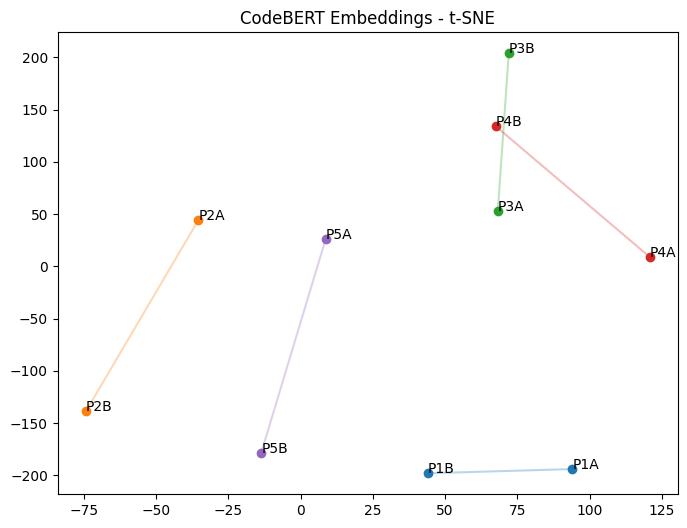

In [13]:
# Reduce to 2D with t-SNE and plot
xy = TSNE(n_components=2, perplexity=3, random_state=42).fit_transform(embeddings)
plt.figure(figsize=(8, 6))

cmap = plt.get_cmap('tab10')

for i in range(len(pairs)):
    idx1, idx2 = i * 2, i * 2 + 1
    color = cmap(i % 10)

    # Plot dots for the pair
    plt.scatter(xy[[idx1, idx2], 0], xy[[idx1, idx2], 1], color=color)

    # Connect them with a lighter shade line
    plt.plot(xy[[idx1, idx2], 0], xy[[idx1, idx2], 1], color=color, alpha=0.3, linestyle='-')

for i, name in enumerate(names):
    plt.annotate(name, xy[i])

plt.title("CodeBERT Embeddings - t-SNE")
plt.savefig("tsne.png", dpi=300, bbox_inches="tight")
plt.show()

## Analyze Code Clones

In [7]:
# Show which plotted pairs are actual clones
for i, p in enumerate(pairs):
    print(f"P{i+1}: {'clone' if p['label'] else 'not clone'}")

P1: clone
P2: clone
P3: clone
P4: clone
P5: clone
